## 1 The CMB angular power spectrum

1. La cantidad equivalente sa $C_\ell$ es el espectro de potencia $P_\ell$
2. La equivalencia de $\delta_{\vec{k}}$ son los coeficientes de la expansión de armónicos $a_{\ell m}$.
3. No, el espectro de potencias $C_\ell$ solo determina un cierto aspecto de los cmpos gaussianos que representan el CMB, así que dos distintas realizaciones con el mismo $C_\ell$ no van a ser los mismos.
4. Van a conservar el promedio y las dimensiones de la caja en espacio de configuraciones.
5. Yo esperaría que representen lo mismo que las $k$, grandes $\ell$ deben representar a la estructura en pequeña escala en espacio real.

## 2 Generate a theoretical CMB power spectrum

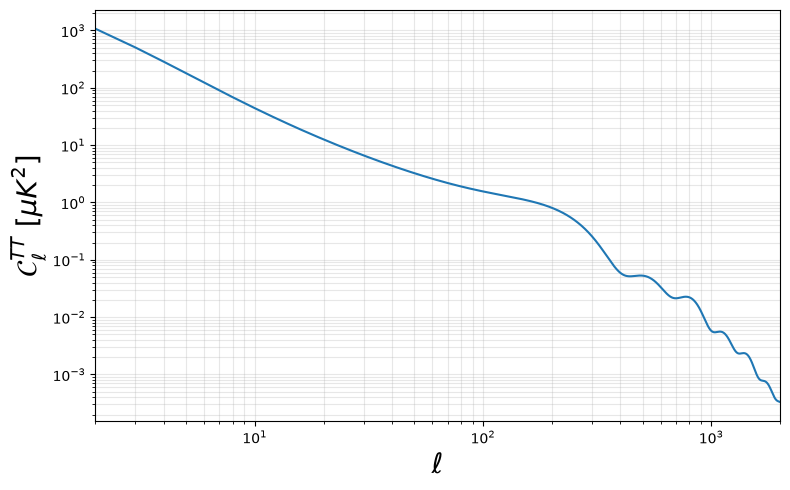

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import camb

SEED = 42
rng = np.random.default_rng(SEED)

h2 = 0.70 ** 2

pars = camb.set_params(H0=70, ombh2=0.05*h2, omch2=0.25*h2)
results = camb.get_results(pars)

Dl = results.get_total_cls(lmax=2000, CMB_unit="muK")[:, 0]
Cl = results.get_total_cls(lmax=2000, CMB_unit="muK", raw_cl=True)[:, 0]
ell = np.arange(Cl.shape[0])

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(ell[2:], Cl[2:], lw=1.5)
#ax.set_xscale('log')
ax.set_xlim(2, ell[-1])
ax.set_xlabel(r'$\ell$', fontsize=20)
ax.set_ylabel(r'$\mathcal{C}_\ell^{TT} \ [\mu K^2]$', fontsize=20)
ax.grid(alpha=0.3, which='both')
fig.tight_layout()
plt.show()

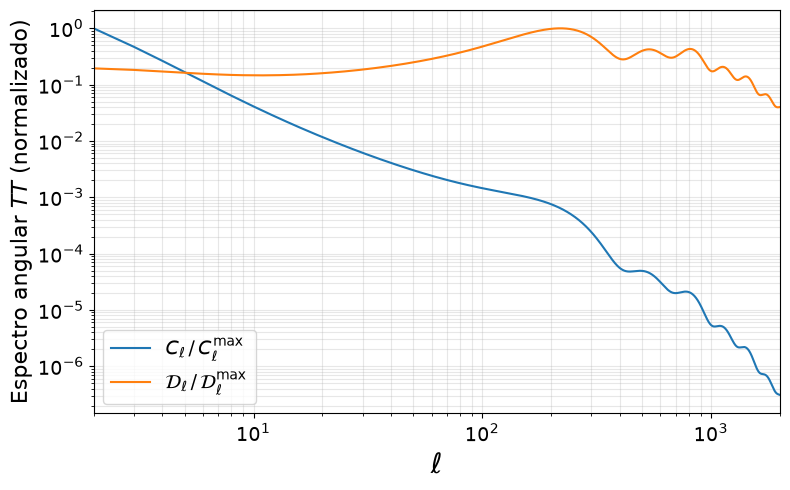

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(ell[2:], Cl[2:] / Cl[2:].max(), lw=1.5, label=r'$C_\ell \,/\, C_\ell^{\max}$')
ax.loglog(ell[2:], Dl[2:] / Dl[2:].max(), lw=1.5, label=r'$\mathcal{D}_\ell \,/\, \mathcal{D}_\ell^{\max}$')
ax.set_xlim(2, ell[-1])
ax.set_xlabel(r'$\ell$', fontsize=20)
ax.set_ylabel(r'Espectro angular $TT$ (normalizado)', fontsize=16)
ax.tick_params(labelsize=14)
ax.legend(fontsize=14)
ax.grid(alpha=0.3, which='both')
fig.tight_layout()
plt.show()

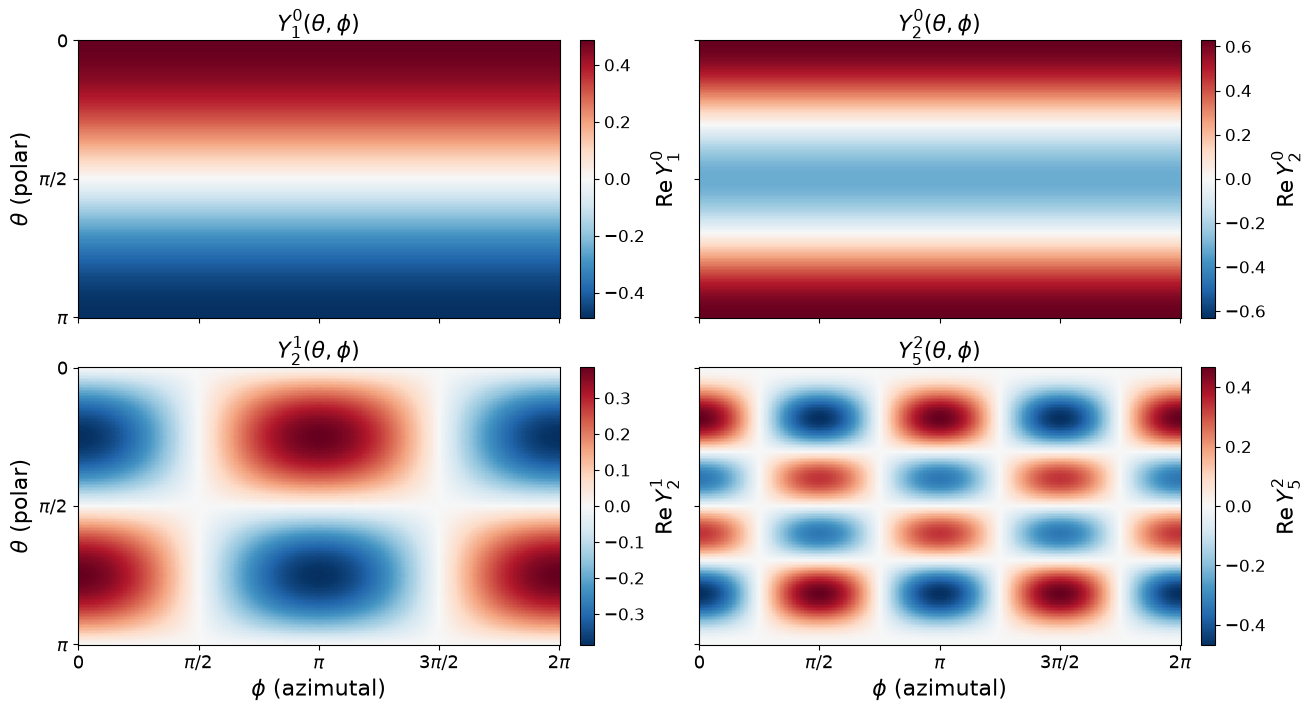

In [3]:
from scipy.special import sph_harm_y

theta = np.linspace(0, np.pi, 181)
phi   = np.linspace(0, 2*np.pi, 361)
AZ, POL = np.meshgrid(phi, theta)

modos = [(1, 0), (2, 0), (2, 1), (5, 2)]
Ys = {(l, m): sph_harm_y(l, m, POL, AZ).real for l, m in modos}

fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos):
    Y = Ys[(l, m)]
    vmax = np.abs(Y).max()                     # escala simétrica: blanco = 0
    im = ax.pcolormesh(AZ, POL, Y, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
    cb = fig.colorbar(im, ax=ax, pad=0.02)
    cb.set_label(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=16)
    cb.ax.tick_params(labelsize=12)
    ax.set_title(rf'$Y_{{{l}}}^{{{m}}}(\theta,\phi)$', fontsize=16)
    ax.set_xticks(np.linspace(0, 2*np.pi, 5), ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'], fontsize=13)
    ax.set_yticks(np.linspace(0, np.pi, 3), ['0', r'$\pi/2$', r'$\pi$'], fontsize=13)
axs[0, 0].invert_yaxis()                       # polo norte (θ=0) arriba (sharey: aplica a todos)
for ax in axs[1]: ax.set_xlabel(r'$\phi$ (azimutal)', fontsize=16)
for ax in axs[:, 0]: ax.set_ylabel(r'$\theta$ (polar)', fontsize=16)
plt.show()

1. Cuando $\ell$ cambia aparecen más franjas horizontales, que representan que el cambio del módulo de $Y_\ell^m$ cambia más seguido en la dirección polar $\theta$.
2. Cuando $m$ cambia aparecen más franjas verticales, que representan que el cambio del módulo de $Y_\ell^m$ cambia más seguido en la dirección azimutal $\phi$, pero también ocurre que los pico se van acumulando en el centro y la amplitud va tendiendo a cero en los polos.
3. Para $\ell = 0$, se tiene una única franja; para $\ell = 1$, dos franjas; para $\ell = 2$, tres franjas, y así sucesivamente. A $\ell = 0, 1, 2,\dots$ yo le asocio, aproximadamente, $\theta \approx \pi / (\ell + 1)$. Esto debido a que, a mayor $\ell$, mayor oscilación en el módulo de $Y_\ell^m$, lo que se traduce a espacio real como mayor resolución a la hora de representar escalas pequeñas del campo.

## 4 Generate random spherical-harmonic coefficients

1. La condición equivlente en espacio de Fourier es $\delta_{-k} = (\delta_k)^*$.
2. La condición de realidad nos dice que $a_{\ell,0} = (a_{\ell,0})^*$, es decir, que un número debe ser igual a su conjugado. Esto solo ocurre si $a_{\ell,0} \in \mathbb{R}$.
3. Ocurriria que la condición de realidad ya no seria válida, por ende el campo en espacio real seria un campo complejo y no podría representar a nuestro campo de temperatura $\Delta T/T$.

In [4]:
coef = np.zeros((21, 41), dtype=np.complex128)
for l in range(1, 21):
    a = rng.normal(0, np.sqrt(Cl[l] / 2), size=l+1)
    b = rng.normal(0, np.sqrt(Cl[l] / 2), size=l)
    right = a[1:] + 1j * b
    left = (-1) ** np.arange(1,l+1) * right.conj()
    coef[l,:2*l+1] = np.concatenate((left[::-1], np.array([np.sqrt(2) * a[0]]), right))

## 5 Generate a CMB realization

In [5]:
theta = np.linspace(0, np.pi, 300, endpoint=False)
phi   = np.linspace(0, 2*np.pi, 300, endpoint=False)
AZ, POL = np.meshgrid(phi, theta)

field = np.zeros_like(AZ, dtype=np.complex128)
for l in range(1, 21):
    for m in range(-l, l+1):
        field += coef[l,l+m] * sph_harm_y(l, m, POL, AZ)

print(np.abs(field.imag).max() / np.abs(field.real).max())

5.393634739353953e-17


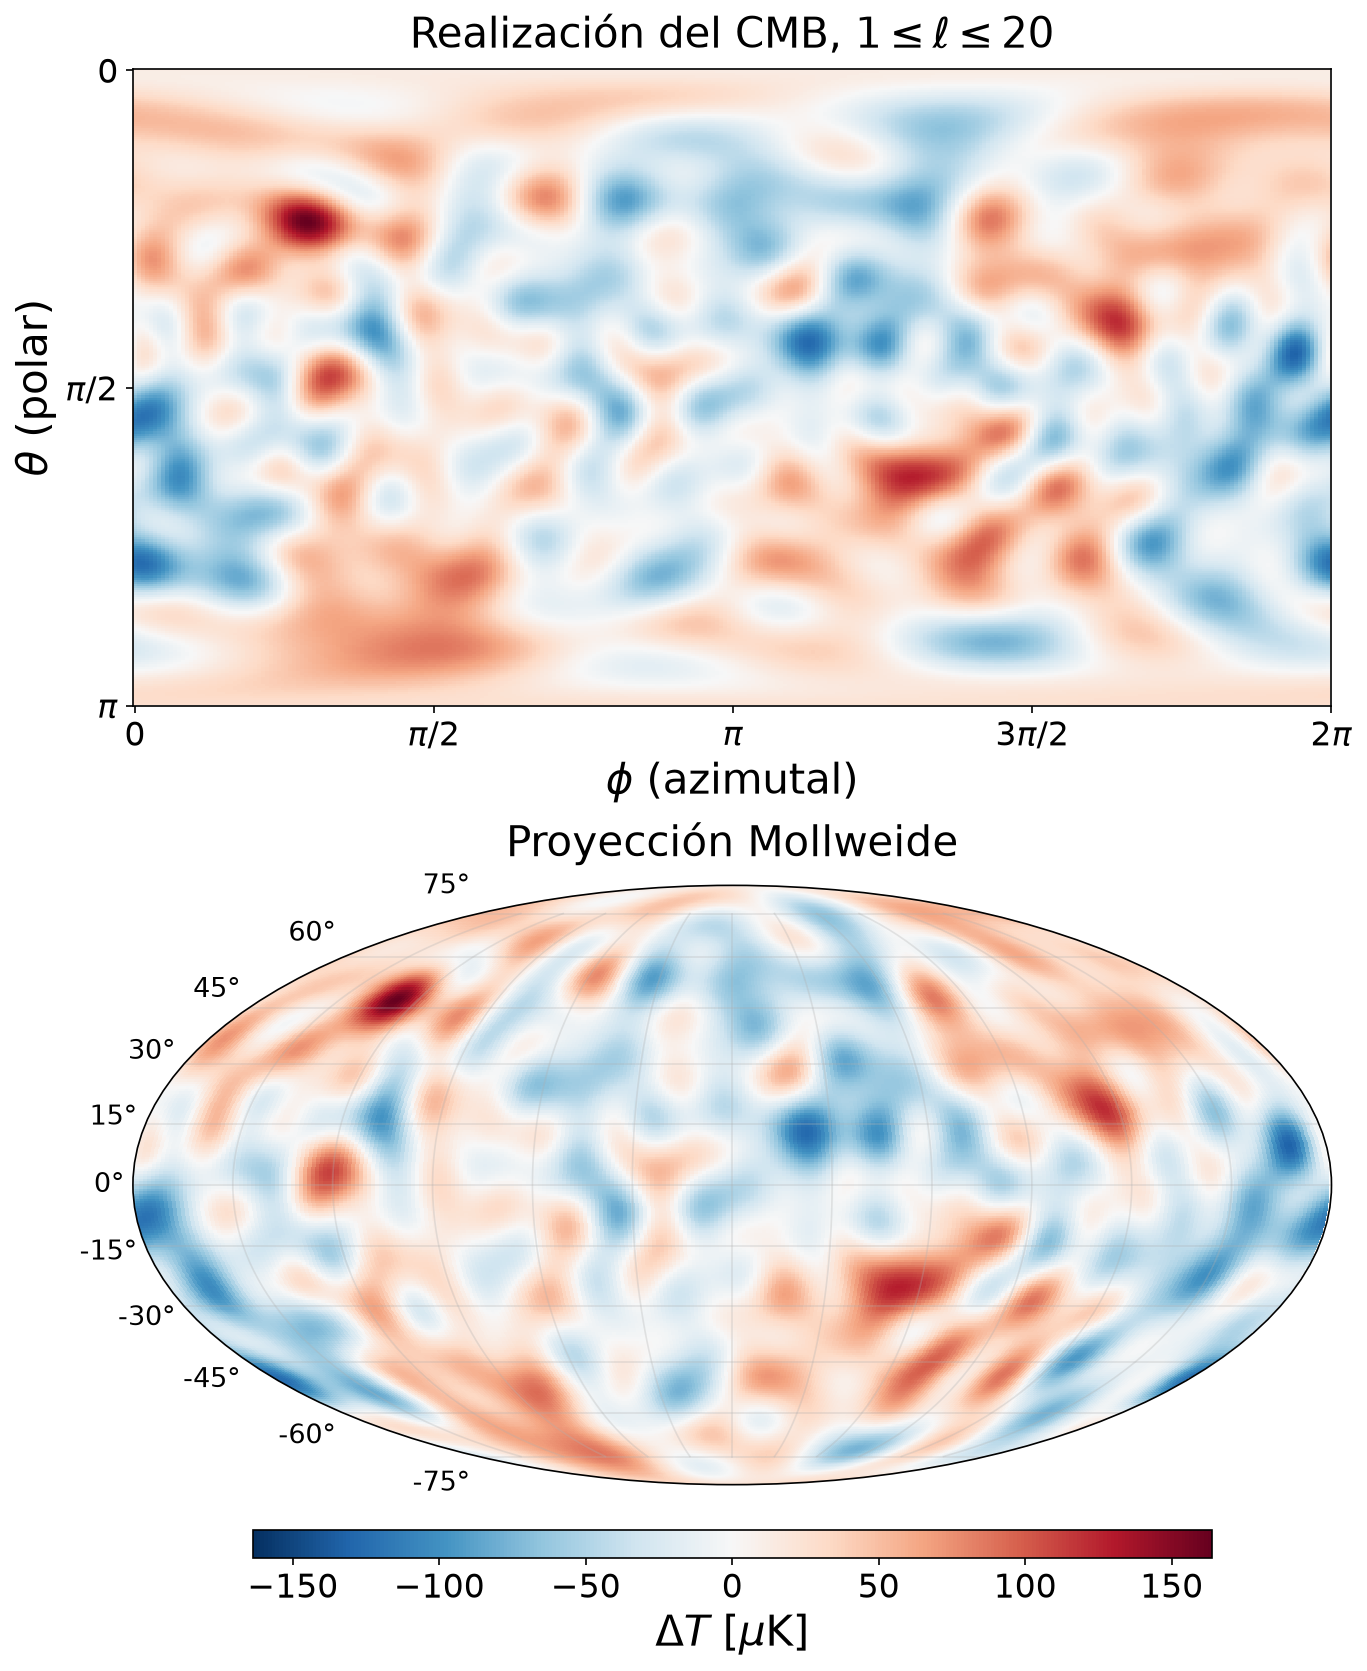

In [6]:
T = field.real                                  # parte imaginaria ~0 (verificado arriba)
vmax = np.abs(T).max()                          # escala simétrica: blanco = 0
kw = dict(cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto', rasterized=True)

fig = plt.figure(figsize=(9, 11), dpi=150, constrained_layout=True)

# Mapa en (phi, theta), como pide la práctica
ax1 = fig.add_subplot(2, 1, 1)
im = ax1.pcolormesh(AZ, POL, T, **kw)
ax1.invert_yaxis()                              # polo norte (θ=0) arriba
ax1.set_xticks(np.linspace(0, 2*np.pi, 5), ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
ax1.set_yticks(np.linspace(0, np.pi, 3), ['0', r'$\pi/2$', r'$\pi$'])
ax1.tick_params(labelsize=16)
ax1.set_xlabel(r'$\phi$ (azimutal)', fontsize=20)
ax1.set_ylabel(r'$\theta$ (polar)', fontsize=20)
ax1.set_title(r'Realización del CMB, $1 \leq \ell \leq 20$', fontsize=20, pad=10)

# Proyección Mollweide, la usual en mapas del CMB
ax2 = fig.add_subplot(2, 1, 2, projection='mollweide')
ax2.pcolormesh(AZ - np.pi, np.pi/2 - POL, T, **kw)
ax2.set_xticklabels([])
ax2.tick_params(labelsize=13)
ax2.grid(alpha=0.3)
ax2.set_title('Proyección Mollweide', fontsize=20, pad=14)

cb = fig.colorbar(im, ax=[ax1, ax2], orientation='horizontal', shrink=0.8, aspect=35, pad=0.02)
cb.set_label(r'$\Delta T\ [\mu\mathrm{K}]$', fontsize=20)
cb.ax.tick_params(labelsize=16)
plt.show()

1. El *plot* solo tiene estructura a gran escala porque la información a pequeña escala está contenida dentro de los $\ell$ grandes y aquí solo se tienen los primero 20.
2. Espero que se comience a definir mucho más la estructura y se vea mucho más definido todo.
3. No, debe de ser otro campo diferente.
4. El promedio debe quedar igual y el tipo de estructura hasta el cuál está definido el campo.

## 6 Does the CMB sky reproduce the input $\mathcal{C}_\ell$?

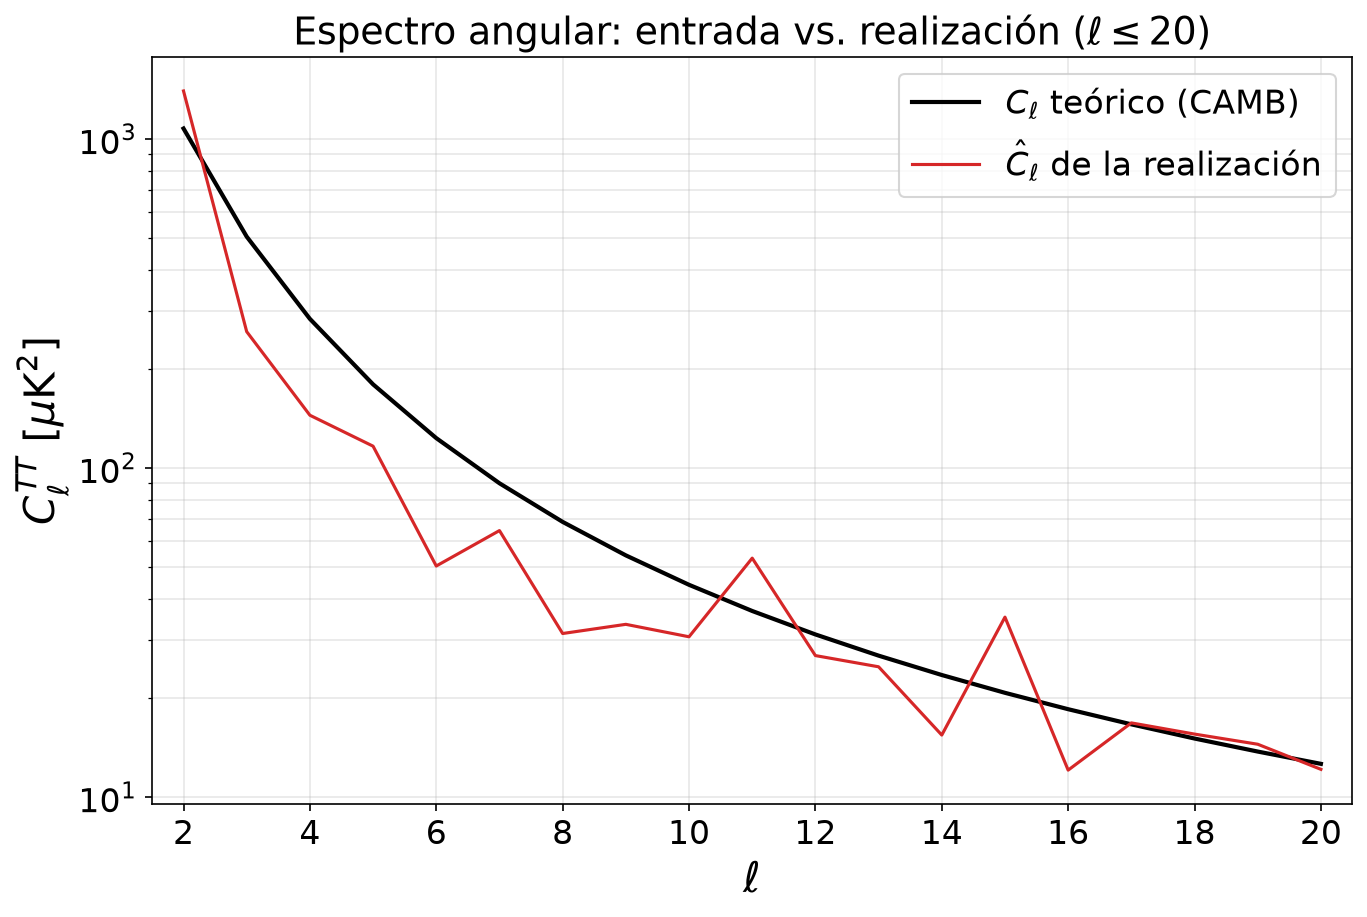

In [7]:
myCl = np.zeros(21)
for l in range(1,21):
    for m in range(-l, l+1):
        myCl[l] += np.abs(coef[l,l+m]) ** 2 / (2*l+1)

l_sim = np.arange(2, 21)                        # C_0 = C_1 = 0 en CAMB: se omiten en escala log

fig, ax = plt.subplots(figsize=(9, 6), dpi=150, constrained_layout=True)
ax.plot(ell[2:21], Cl[2:21], '-', lw=2, color='k', label=r'$C_\ell$ teórico (CAMB)')
ax.plot(l_sim, myCl[2:21], '-', ms=8, color='C3', label=r'$\hat{C}_\ell$ de la realización')
ax.set_yscale('log')
ax.set_xlim(1.5, 20.5)
ax.set_xticks(np.arange(2, 21, 2))
ax.set_xlabel(r'$\ell$', fontsize=20)
ax.set_ylabel(r'$C_\ell^{TT}\ [\mu\mathrm{K}^2]$', fontsize=20)
ax.set_title(r'Espectro angular: entrada vs. realización ($\ell \leq 20$)', fontsize=18)
ax.tick_params(labelsize=16)
ax.legend(fontsize=16)
ax.grid(alpha=0.3, which='both')
plt.show()

1. No, no se reproduce perfectamente el resultado de CAMB porque se están considerando muchos menos $\ell$'s, lo que lleva a ruido en la recreación.
2. Para cada $\ell$, existen $2\ell + 1$ vaores de $m$ que contribuyen a la contribución.
3. Entendido el *scatter* como la dispersión de la estructura, entonces esté pertenece a los valores grandes de $\ell$.
4. Porque da lugar a más $m$ que contribuyen a estimar cada $\hat{\mathcal{C}}_\ell$.

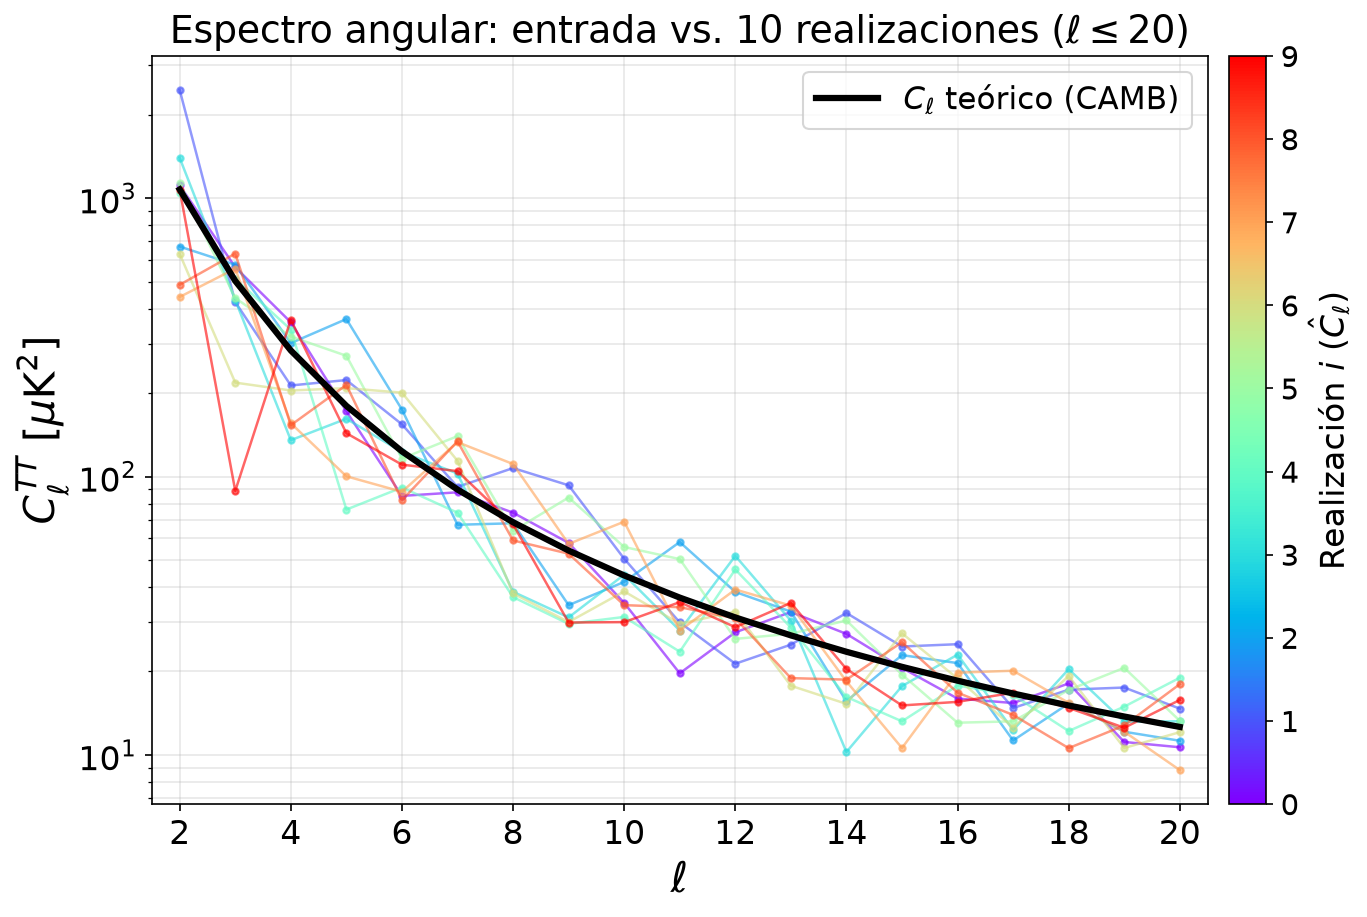

In [8]:
Nr = 10

rng_childs = rng.spawn(Nr)
coef_arr = np.zeros((Nr, 21, 41), dtype=np.complex128)
for i, rc in enumerate(rng_childs):
    for l in range(1, 21):
        a = rc.normal(0, np.sqrt(Cl[l] / 2), size=l+1)
        b = rc.normal(0, np.sqrt(Cl[l] / 2), size=l)
        right = a[1:] + 1j * b
        left = (-1) ** np.arange(1,l+1) * right.conj()
        coef_arr[i, l, :2*l+1] = np.concatenate((left[::-1], np.array([np.sqrt(2) * a[0]]), right))

myCl_arr = np.zeros((Nr, 21))
for i, coef_i in enumerate(coef_arr):
    for l in range(1,21):
        for m in range(-l, l+1):
            myCl_arr[i, l] += np.abs(coef_i[l, l+m]) ** 2 / (2*l+1)

l_sim = np.arange(2, 21)                        # C_0 = C_1 = 0 en CAMB: se omiten en escala log

colores = plt.cm.rainbow(np.linspace(0, 1, Nr))
fig, ax = plt.subplots(figsize=(9, 6), dpi=150, constrained_layout=True)
for i in range(Nr):
    ax.plot(l_sim, myCl_arr[i, 2:21], '-o', lw=1.2, ms=3, color=colores[i], alpha=0.6)
ax.plot(ell[2:21], Cl[2:21], '-', lw=3, color='k', zorder=10, label=r'$C_\ell$ teórico (CAMB)')
ax.set_yscale('log')
ax.set_xlim(1.5, 20.5)
ax.set_xticks(np.arange(2, 21, 2))
ax.set_xlabel(r'$\ell$', fontsize=20)
ax.set_ylabel(r'$C_\ell^{TT}\ [\mu\mathrm{K}^2]$', fontsize=20)
ax.set_title(rf'Espectro angular: entrada vs. {Nr} realizaciones ($\ell \leq 20$)', fontsize=18)
ax.tick_params(labelsize=16)
ax.legend(fontsize=15)
ax.grid(alpha=0.3, which='both')

sm = plt.cm.ScalarMappable(cmap='rainbow', norm=plt.Normalize(0, Nr - 1))
cb = fig.colorbar(sm, ax=ax, pad=0.02)
cb.set_label(r'Realización $i$ ($\hat{C}_\ell$)', fontsize=16)
cb.ax.tick_params(labelsize=14)
plt.show()

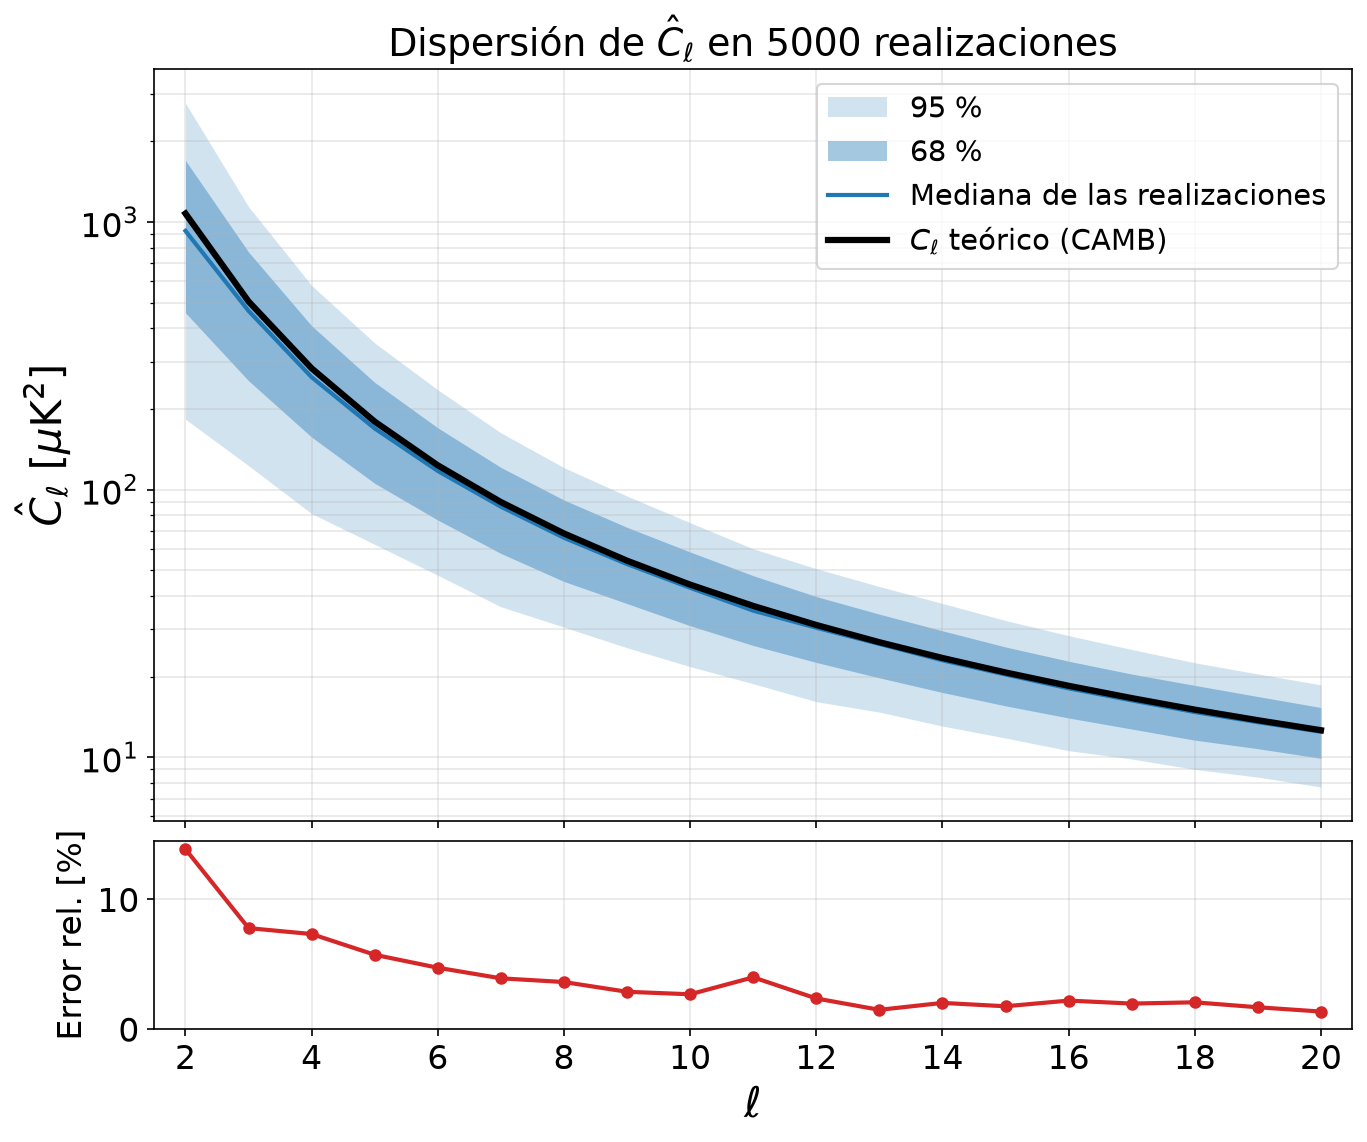

In [9]:
Nr_big = 5000
coef_big = np.zeros((Nr_big, 21, 41), dtype=np.complex128)
for i, rc in enumerate(rng.spawn(Nr_big)):
    for l in range(1, 21):
        a = rc.normal(0, np.sqrt(Cl[l] / 2), size=l+1)
        b = rc.normal(0, np.sqrt(Cl[l] / 2), size=l)
        right = a[1:] + 1j * b
        left = (-1) ** np.arange(1,l+1) * right.conj()
        coef_big[i, l, :2*l+1] = np.concatenate((left[::-1], np.array([np.sqrt(2) * a[0]]), right))
myCl_big = (np.abs(coef_big) ** 2).sum(axis=2) / (2 * np.arange(21) + 1)   # columnas fuera de |m|<=l son 0

p = np.percentile(myCl_big[:, 2:21], [2.5, 16, 50, 84, 97.5], axis=0)
err_rel = 100 * np.abs(p[2] - Cl[2:21]) / Cl[2:21]   # |mediana - C_l(CAMB)| / C_l  [%]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7.5), dpi=150, sharex=True, constrained_layout=True,
                               gridspec_kw={'height_ratios': [4, 1]})
ax1.fill_between(l_sim, p[0], p[4], color='C0', alpha=0.2, lw=0, label='95 %')
ax1.fill_between(l_sim, p[1], p[3], color='C0', alpha=0.4, lw=0, label='68 %')
ax1.plot(l_sim, p[2], '-', lw=2, color='C0', label='Mediana de las realizaciones')
ax1.plot(l_sim, Cl[2:21], '-', lw=3, color='k', zorder=10, label=r'$C_\ell$ teórico (CAMB)')
ax1.set_yscale('log')
ax1.set_ylabel(r'$\hat{C}_\ell\ [\mu\mathrm{K}^2]$', fontsize=20)
ax1.set_title(rf'Dispersión de $\hat{{C}}_\ell$ en {Nr_big} realizaciones', fontsize=18)
ax1.legend(fontsize=14)

ax2.plot(l_sim, err_rel, '-o', lw=2, ms=5, color='C3')
ax2.set_ylim(0, None)
ax2.set_ylabel(r'Error rel. [%]', fontsize=16)
ax2.set_xlabel(r'$\ell$', fontsize=20)
ax2.set_xlim(1.5, 20.5)
ax2.set_xticks(np.arange(2, 21, 2))

for ax in (ax1, ax2):
    ax.tick_params(labelsize=16)
    ax.grid(alpha=0.3, which='both')
plt.show()

El último plot son 5000 realizaciones a los cuales se les toma la mediana de todas ellas. El error relativo porcentual indica que entre la mediana y el valor obtenido con CAMB se ajustan bastante bien. El error para los valores pequeños de $\ell$ es esperado debido a que hay menos $m$ que contribuyan a la estimación. Muchas realizaciones con pocos modos son perfectamente capaces de replicar una unica realización con muchos modos.

## 7 From a rectangular plot to a sphere

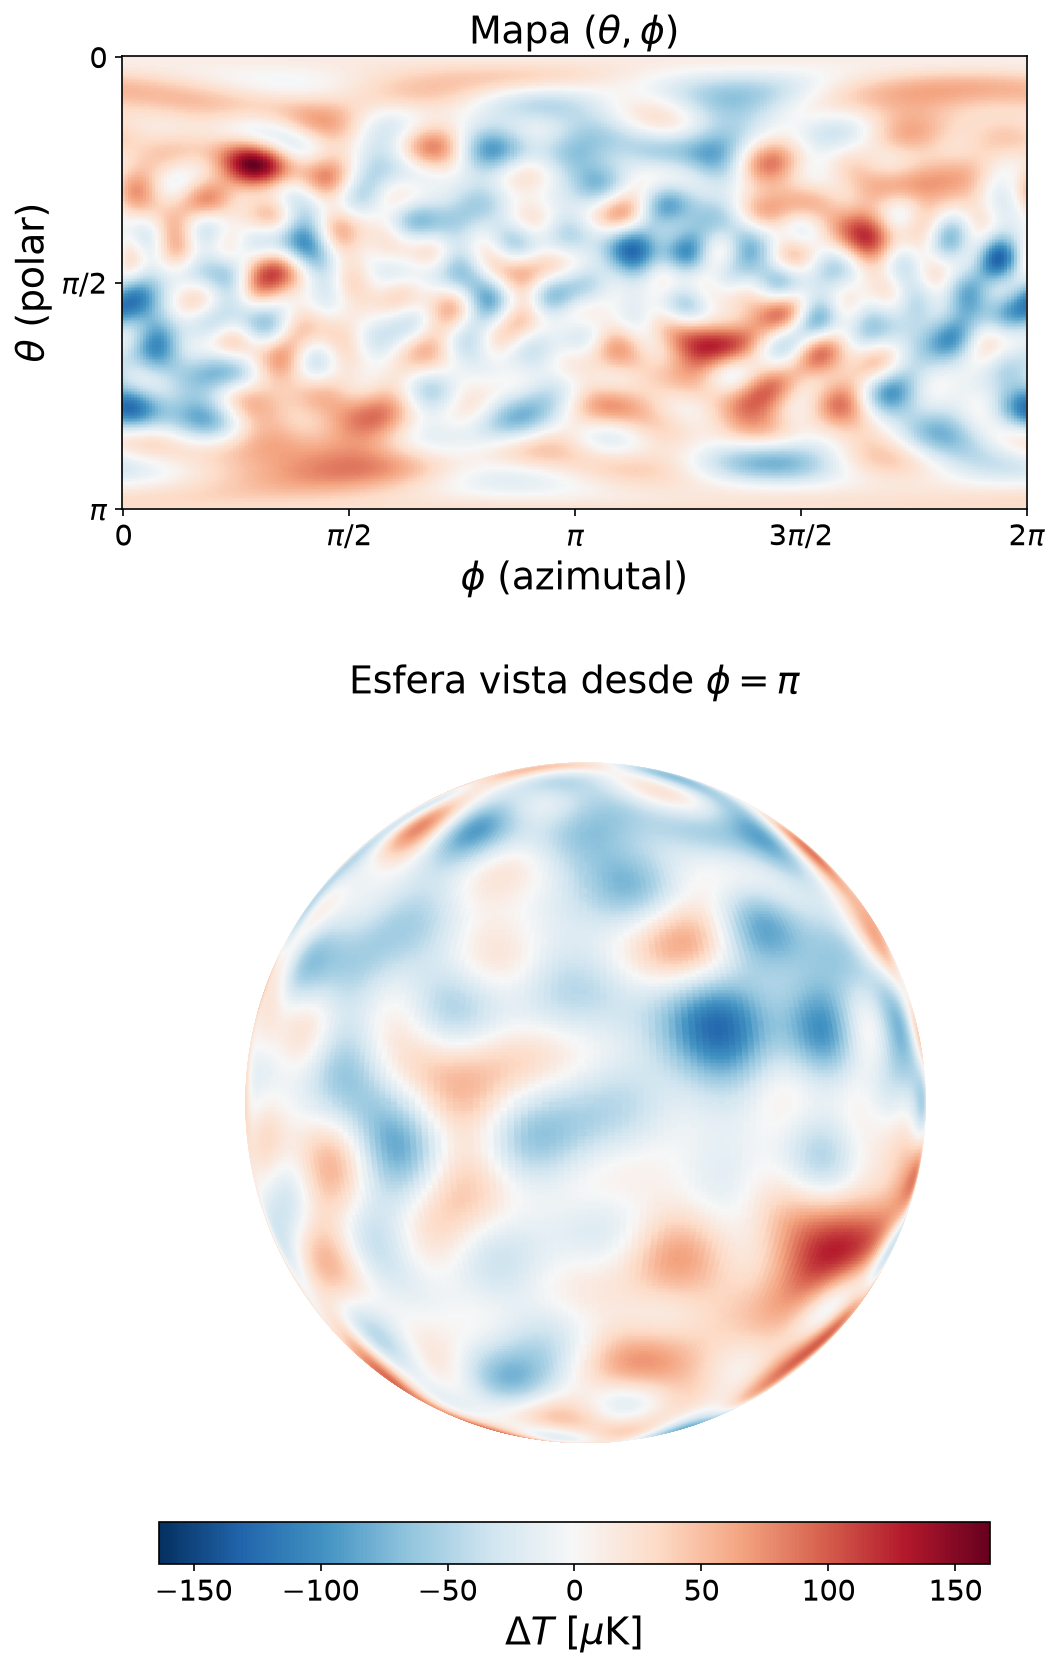

In [10]:
T = field.real
norm = plt.Normalize(-np.abs(T).max(), np.abs(T).max())     # escala simétrica: blanco = 0

fig = plt.figure(figsize=(8, 11), dpi=150, constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.8], hspace=0.08)        # hspace: separación mapa-esfera

ax1 = fig.add_subplot(gs[0])
ax1.pcolormesh(AZ, POL, T, cmap='RdBu_r', norm=norm, rasterized=True)
ax1.invert_yaxis()                                           # polo norte (θ=0) arriba
ax1.set_aspect('equal')                                      # 1 rad = 1 rad: proporción 2:1 (2π × π)
ax1.set_xlabel(r'$\phi$ (azimutal)', fontsize=18)
ax1.set_ylabel(r'$\theta$ (polar)', fontsize=18)
ax1.set_title(r'Mapa $(\theta, \phi)$', fontsize=18)
ax1.set_xticks(np.linspace(0, 2*np.pi, 5), ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
ax1.set_yticks(np.linspace(0, np.pi, 3), ['0', r'$\pi/2$', r'$\pi$'])
ax1.tick_params(labelsize=14)

ax2 = fig.add_subplot(gs[1], projection='3d')
ax2.plot_surface(np.sin(POL) * np.cos(AZ), np.sin(POL) * np.sin(AZ), np.cos(POL),
                 facecolors=plt.cm.RdBu_r(norm(T)), rcount=300, ccount=300, shade=False, rasterized=True)
ax2.view_init(elev=0, azim=180)                              # cara φ = π, el centro del mapa
ax2.set_proj_type('ortho')
ax2.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1))           # mismos límites en x, y, z: esfera redonda
ax2.set_box_aspect((1, 1, 1), zoom=1.4)
ax2.set_axis_off()
ax2.set_title(r'Esfera vista desde $\phi = \pi$', fontsize=18)

cb = fig.colorbar(plt.cm.ScalarMappable(norm, 'RdBu_r'), ax=[ax1, ax2], orientation='horizontal', shrink=0.7, pad=0.0)  # pad pequeño: acerca la barra a la esfera
cb.set_label(r'$\Delta T\ [\mu\mathrm{K}]$', fontsize=18)
cb.ax.tick_params(labelsize=14)
plt.show()

Síntesis con lmax = 57: 130 s
7.642408041467929e-17


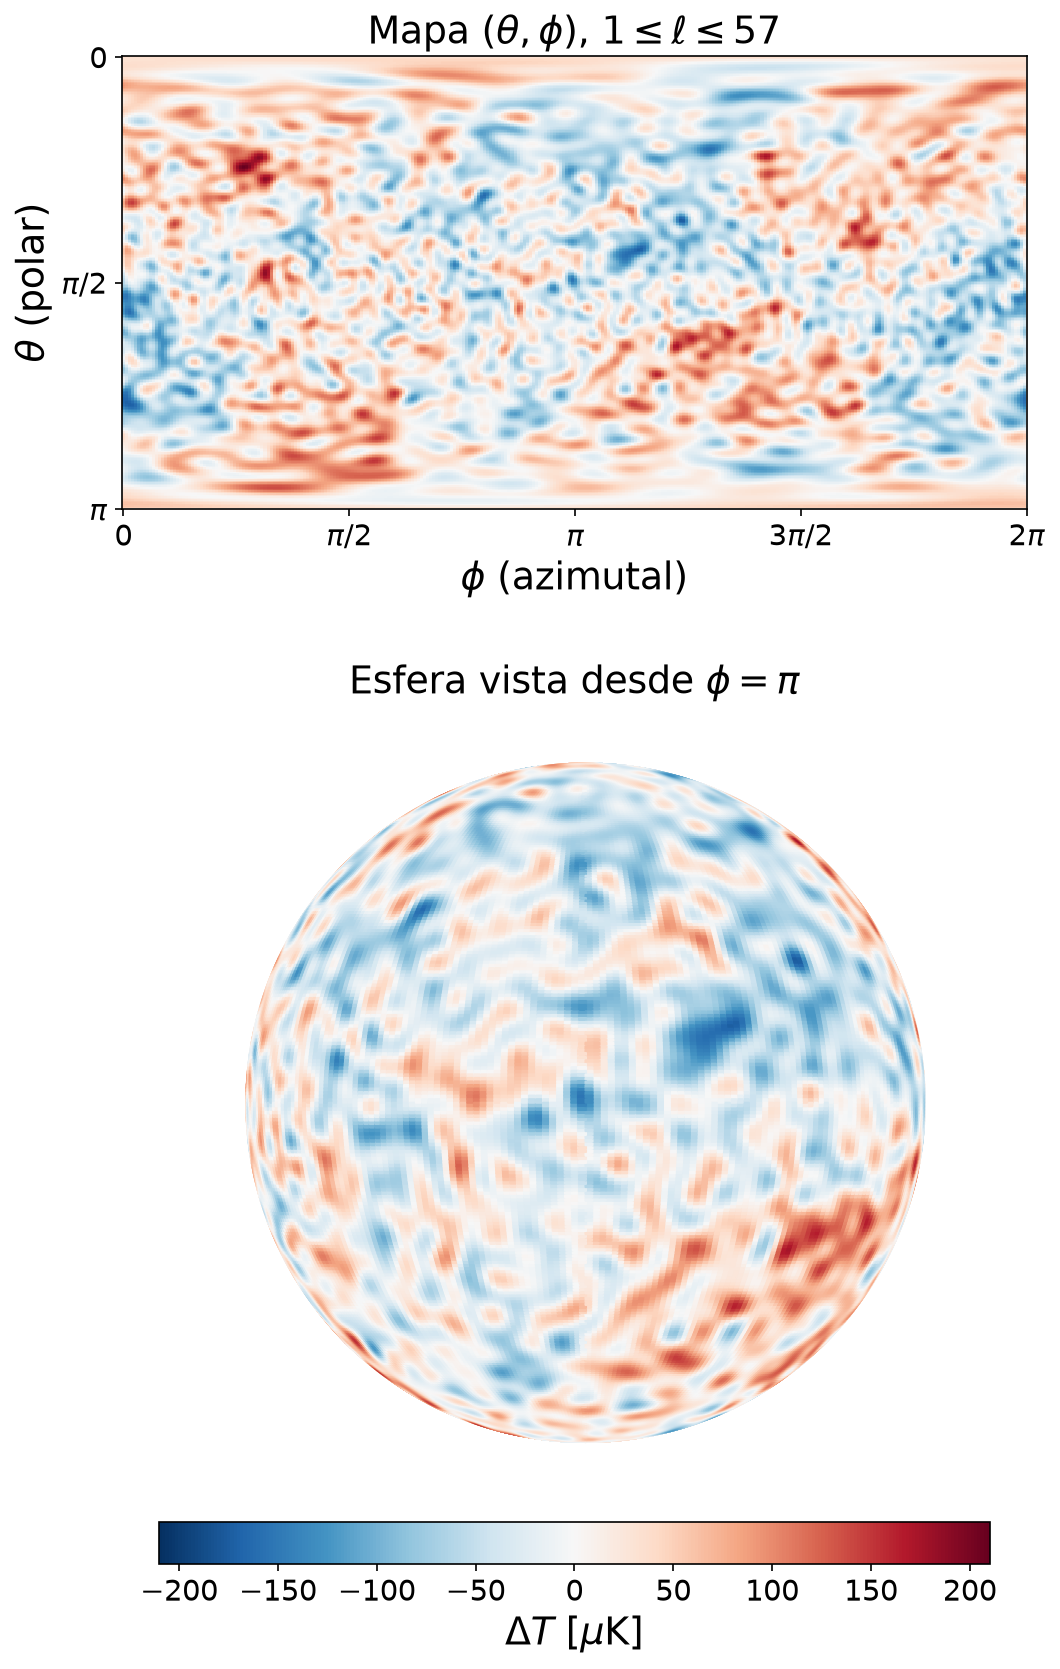

In [ ]:
# Misma realización por fuerza bruta, pero con más multipolos del C_l de CAMB (tarda ~2 min)
import time
lmax_hi = 57
rng_hi = np.random.default_rng(SEED)

coef_hi = np.zeros((lmax_hi + 1, 2*lmax_hi + 1), dtype=np.complex128)
for l in range(1, lmax_hi + 1):
    a = rng_hi.normal(0, np.sqrt(Cl[l] / 2), size=l+1)
    b = rng_hi.normal(0, np.sqrt(Cl[l] / 2), size=l)
    right = a[1:] + 1j * b
    left = (-1) ** np.arange(1, l+1) * right.conj()
    coef_hi[l, :2*l+1] = np.concatenate((left[::-1], np.array([np.sqrt(2) * a[0]]), right))

t0 = time.time()
field_hi = np.zeros_like(AZ, dtype=np.complex128)
for l in range(1, lmax_hi + 1):
    for m in range(-l, l+1):
        field_hi += coef_hi[l, l+m] * sph_harm_y(l, m, POL, AZ)
print(f'Síntesis con lmax = {lmax_hi}: {time.time() - t0:.0f} s')
print(np.abs(field_hi.imag).max() / np.abs(field_hi.real).max())

T = field_hi.real
norm = plt.Normalize(-np.abs(T).max(), np.abs(T).max())     # escala simétrica: blanco = 0

fig = plt.figure(figsize=(8, 11), dpi=150, constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.8], hspace=0.08)        # hspace: separación mapa-esfera

ax1 = fig.add_subplot(gs[0])
ax1.pcolormesh(AZ, POL, T, cmap='RdBu_r', norm=norm, rasterized=True)
ax1.invert_yaxis()                                           # polo norte (θ=0) arriba
ax1.set_aspect('equal')                                      # 1 rad = 1 rad: proporción 2:1 (2π × π)
ax1.set_xlabel(r'$\phi$ (azimutal)', fontsize=18)
ax1.set_ylabel(r'$\theta$ (polar)', fontsize=18)
ax1.set_title(rf'Mapa $(\theta, \phi)$, $1 \leq \ell \leq {lmax_hi}$', fontsize=18)
ax1.set_xticks(np.linspace(0, 2*np.pi, 5), ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
ax1.set_yticks(np.linspace(0, np.pi, 3), ['0', r'$\pi/2$', r'$\pi$'])
ax1.tick_params(labelsize=14)

ax2 = fig.add_subplot(gs[1], projection='3d')
ax2.plot_surface(np.sin(POL) * np.cos(AZ), np.sin(POL) * np.sin(AZ), np.cos(POL),
                 facecolors=plt.cm.RdBu_r(norm(T)), rcount=300, ccount=300, shade=False, rasterized=True)
ax2.view_init(elev=0, azim=180)                              # cara φ = π, el centro del mapa
ax2.set_proj_type('ortho')
ax2.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1))           # mismos límites en x, y, z: esfera redonda
ax2.set_box_aspect((1, 1, 1), zoom=1.4)
ax2.set_axis_off()
ax2.set_title(r'Esfera vista desde $\phi = \pi$', fontsize=18)

cb = fig.colorbar(plt.cm.ScalarMappable(norm, 'RdBu_r'), ax=[ax1, ax2], orientation='horizontal', shrink=0.7, pad=0.0)  # pad pequeño: acerca la barra a la esfera
cb.set_label(r'$\Delta T\ [\mu\mathrm{K}]$', fontsize=18)
cb.ax.tick_params(labelsize=14)
plt.show()

La idea del por qué es que los polos se ven como difuminados en los *plots* 2D es debido a que se está estirando las regiones cerca de los polos para poder representarlo en 2D.

## 8 A controlled experiment

Conforme $\ell_\text{max}$ vaya creaciendo, cada vez más se van a ir definición los bordes de la estructura que se puede distinguir en el plot.

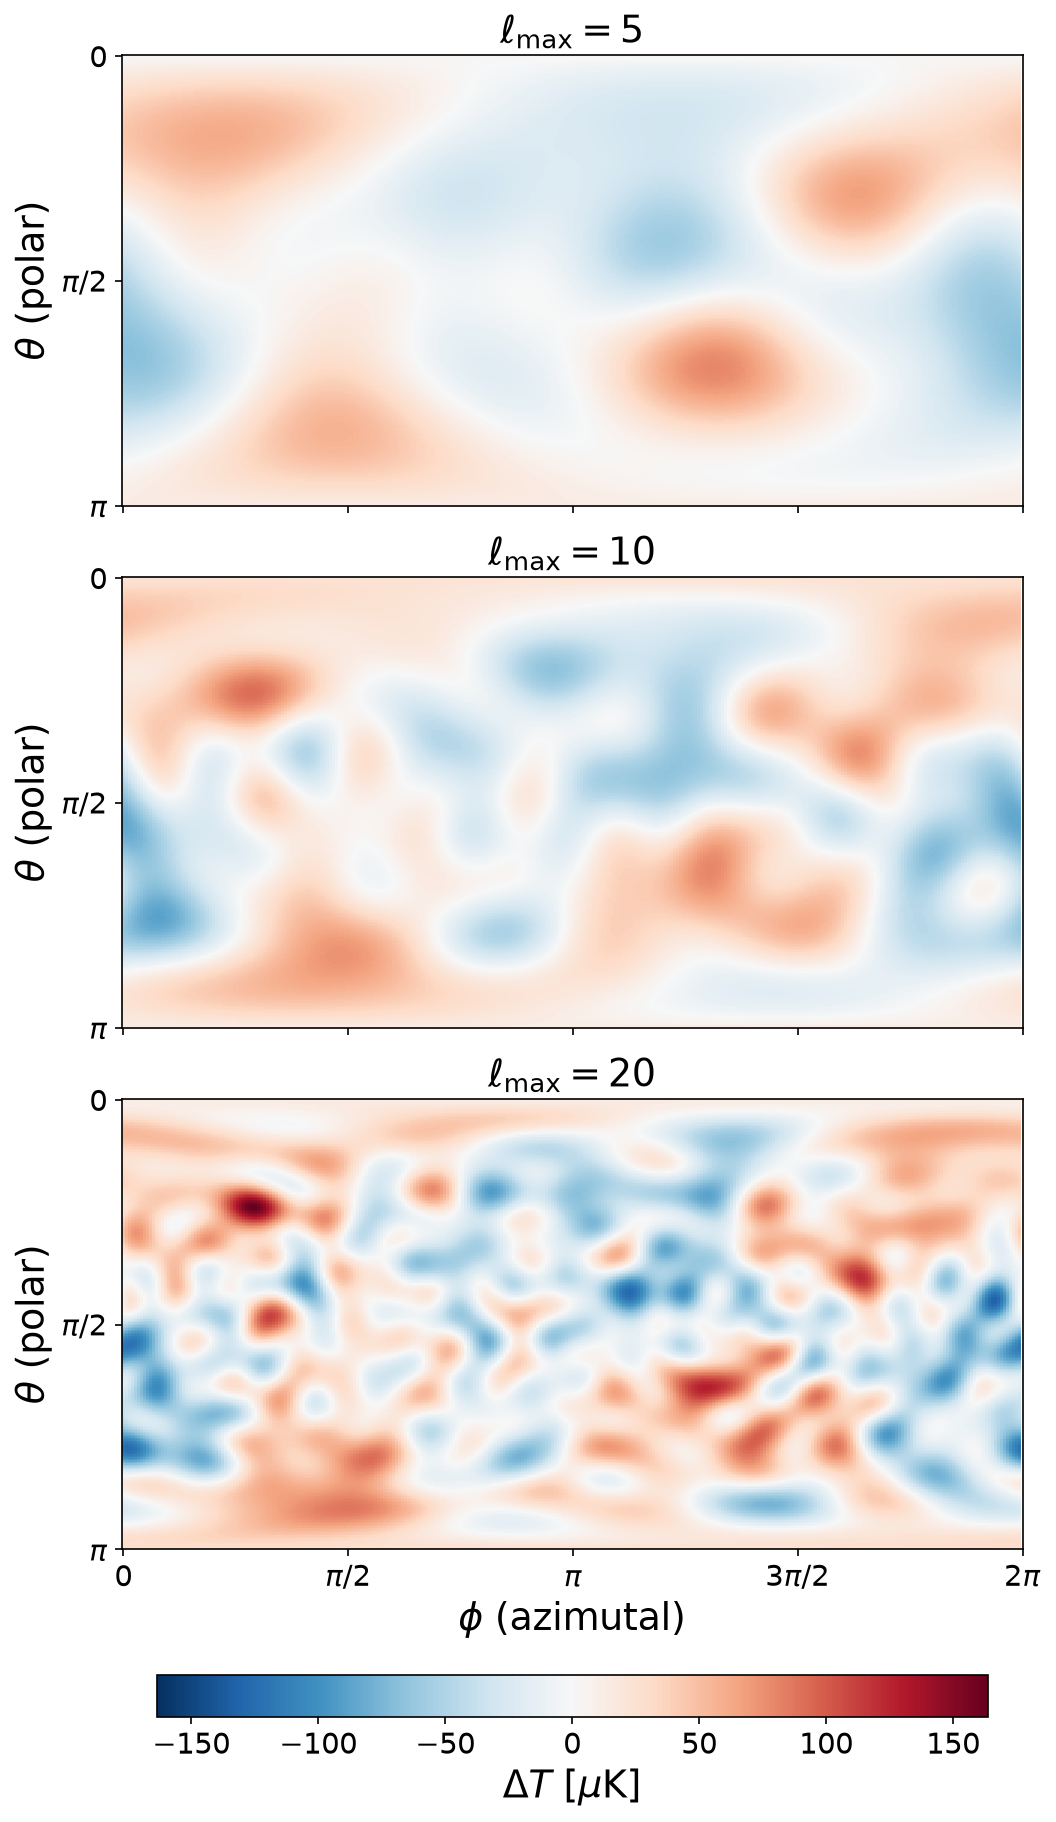

In [12]:
theta = np.linspace(0, np.pi, 300, endpoint=False)
phi   = np.linspace(0, 2*np.pi, 300, endpoint=False)
AZ, POL = np.meshgrid(phi, theta)

field_max = np.zeros((3, *AZ.shape), dtype=np.complex128)
for i, l_max in enumerate([5, 10, 20]):
    for l in range(1, l_max + 1):
        for m in range(-l, l+1):
            field_max[i, :] += coef[l,l+m] * sph_harm_y(l, m, POL, AZ)

l_maxs = [5, 10, 20]
T3 = field_max.real
norm = plt.Normalize(-np.abs(T3).max(), np.abs(T3).max())   # misma escala para los tres mapas

fig, axs = plt.subplots(3, 1, figsize=(8, 12), dpi=150, sharex=True, constrained_layout=True)
for ax, T, l_max in zip(axs, T3, l_maxs):
    im = ax.pcolormesh(AZ, POL, T, cmap='RdBu_r', norm=norm, rasterized=True)
    ax.invert_yaxis()                                        # polo norte (θ=0) arriba
    ax.set_aspect('equal')
    ax.set_yticks(np.linspace(0, np.pi, 3), ['0', r'$\pi/2$', r'$\pi$'])
    ax.set_ylabel(r'$\theta$ (polar)', fontsize=18)
    ax.set_title(rf'$\ell_\mathrm{{max}} = {l_max}$', fontsize=18)
    ax.tick_params(labelsize=14)
axs[-1].set_xticks(np.linspace(0, 2*np.pi, 5), ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
axs[-1].set_xlabel(r'$\phi$ (azimutal)', fontsize=18)

cb = fig.colorbar(im, ax=axs, orientation='horizontal', shrink=0.7, pad=0.02)
cb.set_label(r'$\Delta T\ [\mu\mathrm{K}]$', fontsize=18)
cb.ax.tick_params(labelsize=14)
plt.show()

### Connection with the previous practical

La idea detras de los espectros de potencias $P(k)$ y $\mathcal{C}_\ell$ son escensialmente las mismas, ambos métodos hacen la cuenta de la varianza, slvo por una constante, y buscan expresar lo mismo, pero mediante una descomposición alternativa, que no diferente, conveniente para cada caso de uso apropiado. La descomposición en armónicos esféricos sirve cuando se está tratando con campos esféricos, cosa que con Fourier se puede hacer muy complicado. La equivalencias con 1 a 1 debido a que no se está cambiando ningún significado ni buscando conceptos diferentes.